In [ ]:
# Célula 1
!git clone https://github.com/roneysco/Fake.br-Corpus.git

fatal: destination path 'Fake.br-Corpus' already exists and is not an empty directory.


In [ ]:
# Célula 2: dados
import os
import time
import pandas as pd

def ler_noticias(pasta, label):
    dados = []
    for nome in sorted(os.listdir(pasta)):
        with open(os.path.join(pasta, nome), "r", encoding="utf-8") as f:
            dados.append({"texto": f.read(), "label": label})
    return dados

df = pd.DataFrame(ler_noticias("Fake.br-Corpus/full_texts/true", 0) + ler_noticias("Fake.br-Corpus/full_texts/fake", 1))
df["texto_truncado"] = df["texto"].apply(lambda t: " ".join(t.split()[:150]))
novo = pd.read_csv("/corpus_atualizado_v2.csv")

print("Fake.br:", df.shape)
print("Corpus novo:", novo.shape, novo["label"].value_counts().to_dict())

Fake.br: (7200, 3)
Corpus novo: (100, 7) {0: 60, 1: 40}


In [ ]:
# Célula 3: os algoritmos
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

modelos = {
    "Regressão Logística": LogisticRegression(max_iter=1000),
    "SVM linear": LinearSVC(),
    "Naive Bayes": MultinomialNB(),
    "Passive Aggressive": SGDClassifier(loss="hinge", penalty=None, learning_rate="pa1", eta0=1.0, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

def novo_pipeline(clf):
    return make_pipeline(TfidfVectorizer(max_features=5000), clf)

In [ ]:
# Célula 4: Teste 1, comparação no Fake.br (validação cruzada)
from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
linhas = []
for nome, clf in modelos.items():
    t0 = time.time()
    r = cross_validate(novo_pipeline(clf), df["texto"], df["label"], cv=cv, scoring=["accuracy", "f1_macro"])
    linhas.append({"modelo": nome, "acuracia": r["test_accuracy"].mean(), "desvio": r["test_accuracy"].std(),
                   "f1_macro": r["test_f1_macro"].mean(), "tempo_s": round(time.time() - t0)})
    print(nome, "ok")

resultado_a = pd.DataFrame(linhas).round(4).sort_values("acuracia", ascending=False)
print(resultado_a.to_string(index=False))

Regressão Logística ok
SVM linear ok
Naive Bayes ok
Passive Aggressive ok
Random Forest ok
             modelo  acuracia  desvio  f1_macro  tempo_s
         SVM linear    0.9646  0.0033    0.9646       24
      Random Forest    0.9583  0.0053    0.9583       87
 Passive Aggressive    0.9582  0.0051    0.9582       25
Regressão Logística    0.9536  0.0047    0.9536       33
        Naive Bayes    0.8800  0.0060    0.8797       25


In [ ]:
# Célula 5: Teste 2, treina no Fake.br e testa no corpus novo
from sklearn.metrics import accuracy_score, f1_score, recall_score

linhas = []
for nome, clf in modelos.items():
    pipe = novo_pipeline(clf)
    pipe.fit(df["texto_truncado"], df["label"])
    prev = pipe.predict(novo["texto_truncado"])
    linhas.append({
        "modelo": nome,
        "acuracia": accuracy_score(novo["label"], prev),
        "f1_macro": f1_score(novo["label"], prev, average="macro"),
        "acerto_falsas": recall_score(novo["label"], prev, pos_label=1),
        "acerto_verdadeiras": recall_score(novo["label"], prev, pos_label=0),
    })

resultado_b = pd.DataFrame(linhas).round(4).sort_values("acuracia", ascending=False)
print(resultado_b.to_string(index=False))

             modelo  acuracia  f1_macro  acerto_falsas  acerto_verdadeiras
Regressão Logística      0.89    0.8839          0.825              0.9333
      Random Forest      0.85    0.8416          0.775              0.9000
         SVM linear      0.84    0.8284          0.725              0.9167
 Passive Aggressive      0.83    0.8236          0.800              0.8500
        Naive Bayes      0.80    0.7772          0.600              0.9333


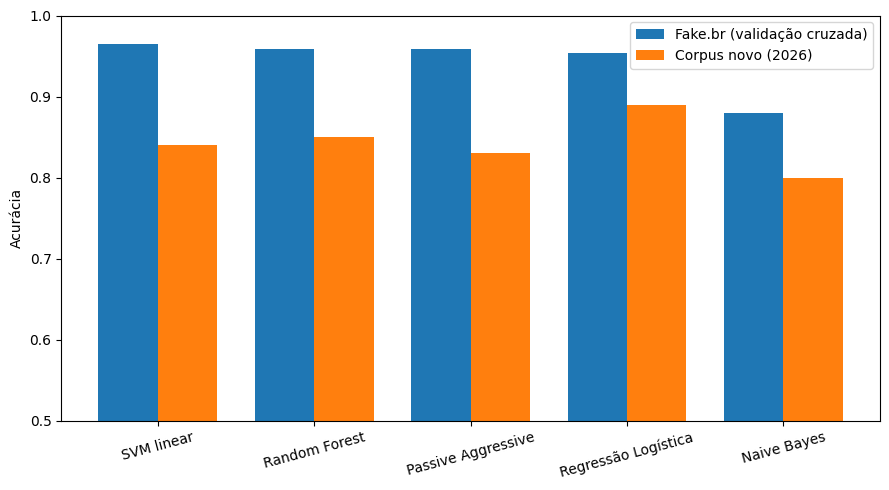

In [ ]:
# Célula 6: gráfico comparativo e salvar os resultados
import matplotlib.pyplot as plt

comp = resultado_a[["modelo", "acuracia"]].merge(resultado_b[["modelo", "acuracia"]], on="modelo", suffixes=("_fakebr", "_novo"))
x = range(len(comp))
w = 0.38
plt.figure(figsize=(9, 5))
plt.bar([i - w / 2 for i in x], comp["acuracia_fakebr"], w, label="Fake.br (validação cruzada)")
plt.bar([i + w / 2 for i in x], comp["acuracia_novo"], w, label="Corpus novo (2026)")
plt.xticks(list(x), comp["modelo"], rotation=15)
plt.ylim(0.5, 1.0)
plt.ylabel("Acurácia")
plt.legend()
plt.tight_layout()
plt.show()

resultado_a.to_csv("resultado_fakebr.csv", index=False)
resultado_b.to_csv("resultado_corpus_novo.csv", index=False)